In [3]:
import numpy as np
import matplotlib.pyplot as plt
from numba import jit
from ipywidgets import interact,IntSlider

# First we write the functions for our CFD solver

In [2]:
# Linear interpolate function
@jit(nopython=True,fastmath=True)
def linear_interp(val1,dx1,val2,dx2):
    return (val1*dx2+val2*dx1)/(dx1+dx2)

# CFD solver
@jit(nopython=True)
def CFD_EDACM(P,U,V,rho,nu,beta,dx,dy):
    m=len(dx)
    n=len(dy)
    der_p=np.zeros_like(P)
    der_u=np.zeros_like(U)
    der_v=np.zeros_like(V)
    for i in range(1,m-1):
        for j in range(1,n-1):
            # First let us interpolate the values at the faces
            P_east=linear_interp(P[i,j],dx[i],P[i+1,j],dx[i+1])
            P_west=linear_interp(P[i-1,j],dx[i-1],P[i,j],dx[i])
            P_north=linear_interp(P[i,j],dy[j],P[i,j+1],dy[j+1])
            P_south=linear_interp(P[i,j-1],dy[j-1],P[i,j],dy[j])
            
            U_east=linear_interp(U[i,j],dx[i],U[i+1,j],dx[i+1])
            U_west=linear_interp(U[i-1,j],dx[i-1],U[i,j],dx[i])
            U_north=linear_interp(U[i,j],dy[j],U[i,j+1],dy[j+1])
            U_south=linear_interp(U[i,j-1],dy[j-1],U[i,j],dy[j])
            
            V_east=linear_interp(V[i,j],dx[i],V[i+1,j],dx[i+1])
            V_west=linear_interp(V[i-1,j],dx[i-1],V[i,j],dx[i])
            V_north=linear_interp(V[i,j],dy[j],V[i,j+1],dy[j+1])
            V_south=linear_interp(V[i,j-1],dy[j-1],V[i,j],dy[j])
            
            # Writing the convective terms
            con_p_x=beta*(U_east-U_west)/dx[i]
            con_p_y=beta*(V_north-V_south)/dy[j]
            con_u_x=(U_east**2-U_west**2)/dx[i]
            con_u_y=(U_north*V_north-U_south*V_south)/dy[j]
            con_v_x=(U_east*V_east-U_west*V_west)/dx[i]
            con_v_y=(V_north**2-V_south**2)/dy[j]
            pressure_u=(P_east-P_west)/(rho*dx[i])
            pressure_v=(P_north-P_south)/(rho*dy[j])
            
            # Now we find the gradients at the faces and write the diffusion terms 
            dpdx_e=(P[i+1,j]-P[i,j])/(0.5*(dx[i]+dx[i+1]))
            dpdx_w=(P[i,j]-P[i-1,j])/(0.5*(dx[i-1]+dx[i]))
            dpdy_n=(P[i,j+1]-P[i,j])/(0.5*(dy[j]+dy[j+1]))
            dpdy_s=(P[i,j]-P[i,j-1])/(0.5*(dy[j-1]+dy[j]))
            diff_p_x=nu*(dpdx_e-dpdx_w)/dx[i]
            diff_p_y=nu*(dpdy_n-dpdy_s)/dy[j]
            
            dudx_e=(U[i+1,j]-U[i,j])/(0.5*(dx[i]+dx[i+1]))
            dudx_w=(U[i,j]-U[i-1,j])/(0.5*(dx[i-1]+dx[i]))
            dudy_n=(U[i,j+1]-U[i,j])/(0.5*(dy[j]+dy[j+1]))
            dudy_s=(U[i,j]-U[i,j-1])/(0.5*(dy[j-1]+dy[j]))
            diff_u_x=nu*(dudx_e-dudx_w)/dx[i]
            diff_u_y=nu*(dudy_n-dudy_s)/dy[j]
            
            dvdx_e=(V[i+1,j]-V[i,j])/(0.5*(dx[i]+dx[i+1]))
            dvdx_w=(V[i,j]-V[i-1,j])/(0.5*(dx[i-1]+dx[i]))
            dvdy_n=(V[i,j+1]-V[i,j])/(0.5*(dy[j]+dy[j+1]))
            dvdy_s=(V[i,j]-V[i,j-1])/(0.5*(dy[j-1]+dy[j]))
            diff_v_x=nu*(dvdx_e-dvdx_w)/dx[i]
            diff_v_y=nu*(dvdy_n-dvdy_s)/dy[j]
            
            
            der_p[i,j]=diff_p_x+diff_p_y-con_p_x-con_p_y
            der_u[i,j]=diff_u_x+diff_u_y-con_u_x-con_u_y-pressure_u
            der_v[i,j]=diff_v_x+diff_v_y-con_v_x-con_v_y-pressure_v
            
    return der_p,der_u,der_v
          
            

# Now we write immersed boundary methods

In [3]:
@jit(nopython=True)
def IBM_forcing_der(U,V,x_c,y_c,lag_x,lag_y,timestep):
    der_u=np.zeros_like(U)
    der_v=np.zeros_like(V)
    m=len(x_c)
    n=len(y_c)
    neigh=3
    # iterating over all the lagrangian points
    for lag_ind in range(0,len(lag_x),1):
        lx=lag_x[lag_ind]
        ly=lag_y[lag_ind]
        # finding the nearest neighbours
        near_i=0
        near_j=0
        for i in range(0,m-1):
            if x_c[i]<lx and lx<=x_c[i+1]:
                near_i=i+0
                break
        for j in range(0,n-1):
            if y_c[j]<ly and ly<=y_c[j+1]:
                near_j=j+0
                break
        #Make calculations for the nearest neighbours
        U_int=0.0
        V_int=0.0
        dx_h=x_c[near_i+1]-x_c[near_i]
        dy_h=y_c[near_j+1]-y_c[near_j]
        #Interpolation Operation
        for i_ind in range(near_i-neigh+1,near_i+neigh+1):
            for j_ind in range(near_j-neigh+1,near_j+neigh+1):
                x_eu=x_c[i_ind]
                y_eu=y_c[j_ind]
                rx=abs(x_eu-lx)/dx_h
                ry=abs(y_eu-ly)/dy_h
                delta_x=0.0
                delta_y=0.0
                if rx<=2.0:
                    delta_x=0.25*(1+np.cos(0.5*np.pi*rx))
                if ry<=2.0:
                    delta_y=0.25*(1+np.cos(0.5*np.pi*ry))
                delta=delta_x*delta_y
                U_int+=delta*U[i_ind,j_ind]
                V_int+=delta*V[i_ind,j_ind]
            
        # Forcing computation
        fx=(-1.0)*U_int/timestep
        fy=(-1.0)*V_int/timestep
        
        # Spreading Operation
        for i_ind in range(near_i-neigh+1,near_i+neigh+1):
            for j_ind in range(near_j-neigh+1,near_j+neigh+1):
                x_eu=x_c[i_ind]
                y_eu=y_c[j_ind]
                rx=abs(x_eu-lx)/dx_h
                ry=abs(y_eu-ly)/dy_h
                delta_x=0.0
                delta_y=0.0
                if rx<=2.0:
                    delta_x=0.25*(1+np.cos(0.5*np.pi*rx))
                if ry<=2.0:
                    delta_y=0.25*(1+np.cos(0.5*np.pi*ry))
                delta=delta_x*delta_y
                der_u[i_ind,j_ind]+=delta*fx
                der_v[i_ind,j_ind]+=delta*fy      
                
    return der_u,der_v

# We write the force computations

In [4]:
# Compute net force on body
@jit(nopython=True)
def IBM_force_computation(U,V,x_c,y_c,lag_x,lag_y,timestep,rho):
    m=len(x_c)
    n=len(y_c)
    neigh=3
    f_x=0.0
    f_y=0.0
    # iterating over all the lagrangian points
    for lag_ind in range(0,len(lag_x),1):
        lx=lag_x[lag_ind]
        ly=lag_y[lag_ind]
        # finding the nearest neighbours
        near_i=0
        near_j=0
        for i in range(0,m-1):
            if x_c[i]<lx and lx<=x_c[i+1]:
                near_i=i+0
                break
        for j in range(0,n-1):
            if y_c[j]<ly and ly<=y_c[j+1]:
                near_j=j+0
                break
        #Make calculations for the nearest neighbours
        U_int=0.0
        V_int=0.0
        dx_h=x_c[near_i+1]-x_c[near_i]
        dy_h=y_c[near_j+1]-y_c[near_j]
        #Interpolation Operation
        for i_ind in range(near_i-neigh+1,near_i+neigh+1):
            for j_ind in range(near_j-neigh+1,near_j+neigh+1):
                x_eu=x_c[i_ind]
                y_eu=y_c[j_ind]
                rx=abs(x_eu-lx)/dx_h
                ry=abs(y_eu-ly)/dy_h
                delta_x=0.0
                delta_y=0.0
                if rx<=2.0:
                    delta_x=0.25*(1+np.cos(0.5*np.pi*rx))
                if ry<=2.0:
                    delta_y=0.25*(1+np.cos(0.5*np.pi*ry))
                delta=delta_x*delta_y
                U_int+=delta*U[i_ind,j_ind]
                V_int+=delta*V[i_ind,j_ind]
            
        # Forcing computation
        f_x+=(rho*dx_h*dy_h)*U_int/timestep
        f_y+=(rho*dx_h*dy_h)*V_int/timestep
        
    return f_x,f_y

# Now writing the time integrators

In [5]:
# TVD Runge Kutta function
def TVD_RK2_integrate(BC_function,P_state,U_state,V_state,U_bound,P_bound,timestep,rho,nu,beta,dx,dy):
    # Implement second order TVD RK for solver only
    dp,du,dv=CFD_EDACM(P_state,U_state,V_state,rho,nu,beta,dx,dy)
    P_temp=P_state+timestep*dp
    U_temp=U_state+timestep*du
    V_temp=V_state+timestep*dv
    # Callling the boundary condition function
    # For our case U_bound is the velocity for wall
    # P is the fixed pressure at a point
    P_temp,U_temp,V_temp=BC_function(P_temp,U_temp,V_temp,U_bound,P_bound)
    dp,du,dv=CFD_EDACM(P_temp,U_temp,V_temp,rho,nu,beta,dx,dy)
    P_new=0.5*(P_state+P_temp)+0.5*timestep*dp
    U_new=0.5*(U_state+U_temp)+0.5*timestep*du
    V_new=0.5*(V_state+V_temp)+0.5*timestep*dv
    P_new,U_new,V_new=BC_function(P_new,U_new,V_new,U_bound,P_bound)
    
    return P_new,U_new,V_new

In [6]:
# TVD RK2 with IBM Forcing
def IBM_RK2(BC_function,P_state,U_state,V_state,U_bound,P_bound,timestep,rho,nu,beta,dx,dy,x_c,y_c,lag_x,lag_y):
    
    dp,du1,dv1=CFD_EDACM(P_state,U_state,V_state,rho,nu,beta,dx,dy)
    du2,dv2=IBM_forcing_der(U_state,V_state,x_c,y_c,lag_x,lag_y,timestep)
    
    P_temp=P_state+timestep*dp
    U_temp=U_state+timestep*(du1+du2)
    V_temp=V_state+timestep*(dv1+dv2)
    
    P_temp,U_temp,V_temp=BC_function(P_temp,U_temp,V_temp,U_bound,P_bound)
    
    dp,du1,dv1=CFD_EDACM(P_temp,U_temp,V_temp,rho,nu,beta,dx,dy)
    du2,dv2=IBM_forcing_der(U_temp,V_temp,x_c,y_c,lag_x,lag_y,timestep)
    
    P_new=0.5*(P_state+P_temp)+0.5*timestep*dp
    U_new=0.5*(U_state+U_temp)+0.5*timestep*(du1+du2)
    V_new=0.5*(V_state+V_temp)+0.5*timestep*(dv1+dv2)
    
    P_new,U_new,V_new=BC_function(P_new,U_new,V_new,U_bound,P_bound)
    
    return P_new,U_new,V_new
    

# Now writing the boundary conditions function

In [7]:
def Lid_bc(P,U,V,U_wall,P_fix):
    m,n=np.shape(P)
    # Wall 1 bc
    P[0,:]=P[1,:]
    U[0,:]=(-1.0)*U[1,:]
    V[0,:]=(-1.0)*V[1,:]
    
    # Wall 2 bc 
    P[m-1,:]=P[m-2,:]
    U[m-1,:]=(-1.0)*U[m-2,:]
    V[m-1,:]=(-1.0)*V[m-2,:]
    
    # Wall 3 bc
    P[:,0]=P[:,1]
    U[:,0]=(-1.0)*U[:,1]
    V[:,0]=(-1.0)*V[:,1]
    
    # Wall 4 bc
    P[:,n-1]=P[:,n-2]
    U[:,n-1]=(2.0*U_wall)-U[:,n-2]
    V[:,n-1]=(-1.0)*V[:,n-2]
    
    # Fixing pressure at the bottom node to be 1
    P[2,2]=P_fix
    
    return P,U,V

# Computing divergence function

In [8]:
@jit(nopython=True,fastmath=True)
def compute_divergence(U,V,dx,dy):
    div_mat=np.zeros_like(U)
    m=len(dx)
    n=len(dy)
    for i in range(2,m-2):
        for j in range(2,n-2):
            # First let us interpolate the values at the faces
            U_east=linear_interp(U[i,j],dx[i],U[i+1,j],dx[i+1])
            U_west=linear_interp(U[i-1,j],dx[i-1],U[i,j],dx[i])
            V_north=linear_interp(V[i,j],dy[j],V[i,j+1],dy[j+1])
            V_south=linear_interp(V[i,j-1],dy[j-1],V[i,j],dy[j])
            
            div_mat[i,j]=((U_east-U_west)/dx[i])+((V_north-V_south)/dy[j]);
    return div_mat
    

# Now we create functions that help in generating the Euler domain

In [2]:
def init_domains(x_eu,y_eu,U_in,P_out):
    x_dom=np.concatenate([[2.0*x_eu[0]-x_eu[1]],x_eu,[2.0*x_eu[-1]-x_eu[-2]]])
    y_dom=np.concatenate([[2.0*y_eu[0]-y_eu[1]],y_eu,[2.0*y_eu[-1]-y_eu[-2]]])
    
    x_c=0.5*(x_dom[1:]+x_dom[:-1])
    y_c=0.5*(y_dom[1:]+y_dom[:-1])
    dx=x_dom[1:]-x_dom[:-1]
    dy=y_dom[1:]-y_dom[:-1]
    m=len(dx)
    n=len(dy)
    xx,yy=np.meshgrid(x_c,y_c,indexing="ij")
    U=U_in*np.ones_like(xx)
    V=np.zeros_like(xx)
    P=P_out*np.ones_like(xx)
    
    return x_c,y_c,dx,dy,xx,yy,P,U,V
    

# Now let us test the code

In [70]:
length=1.0
x=np.concatenate([np.linspace(0,length/2.0,120),np.linspace(length/2.0,length,60)[1:]])
U_in=1.0
P_out=0.0
x_c,y_c,dx,dy,xx,yy,P,U,V=init_domains(x,x,U_in,P_out)

In [71]:
rho=1.0
Re=400
nu=U_in*length/Re
beta=500

In [72]:
n_iter=700000
n_print=1000
n_save=7000
timestep=1e-5

In [73]:
P_array=[]
U_array=[]
V_array=[]
for i in range(n_iter):
    P,U,V=TVD_RK2_integrate(Lid_bc,P,U,V,U_in,P_out,timestep,rho,nu,beta,dx,dy)
    if i%n_print==0:
        print("Iteration "+str(i+1)+"completed")
        div_mat=compute_divergence(U,V,dx,dy)
        print("The maximum value of divergence is :"+str(np.max(np.abs(div_mat))))
    if i%n_save==0:
        print("Iteration "+str(i+1)+"saved")
        P_array.append(np.copy(P))
        U_array.append(np.copy(U))
        V_array.append(np.copy(V))


Iteration 1completed
Iteration 1saved
Iteration 1001completed
Iteration 2001completed
Iteration 3001completed
Iteration 4001completed
Iteration 5001completed
Iteration 6001completed
Iteration 7001completed
Iteration 7001saved
Iteration 8001completed
Iteration 9001completed
Iteration 10001completed
Iteration 11001completed
Iteration 12001completed
Iteration 13001completed
Iteration 14001completed
Iteration 14001saved
Iteration 15001completed
Iteration 16001completed
Iteration 17001completed
Iteration 18001completed
Iteration 19001completed
Iteration 20001completed
Iteration 21001completed
Iteration 21001saved
Iteration 22001completed
Iteration 23001completed
Iteration 24001completed
Iteration 25001completed
Iteration 26001completed
Iteration 27001completed
Iteration 28001completed
Iteration 28001saved
Iteration 29001completed
Iteration 30001completed
Iteration 31001completed
Iteration 32001completed
Iteration 33001completed
Iteration 34001completed
Iteration 35001completed
Iteration 350

Iteration 286001completed
Iteration 287001completed
Iteration 287001saved
Iteration 288001completed
Iteration 289001completed
Iteration 290001completed
Iteration 291001completed
Iteration 292001completed
Iteration 293001completed
Iteration 294001completed
Iteration 294001saved
Iteration 295001completed
Iteration 296001completed
Iteration 297001completed
Iteration 298001completed
Iteration 299001completed
Iteration 300001completed
Iteration 301001completed
Iteration 301001saved
Iteration 302001completed
Iteration 303001completed
Iteration 304001completed
Iteration 305001completed
Iteration 306001completed
Iteration 307001completed
Iteration 308001completed
Iteration 308001saved
Iteration 309001completed
Iteration 310001completed
Iteration 311001completed
Iteration 312001completed
Iteration 313001completed
Iteration 314001completed
Iteration 315001completed
Iteration 315001saved
Iteration 316001completed
Iteration 317001completed
Iteration 318001completed
Iteration 319001completed
Iterat

Iteration 568001completed
Iteration 569001completed
Iteration 570001completed
Iteration 571001completed
Iteration 572001completed
Iteration 573001completed
Iteration 574001completed
Iteration 574001saved
Iteration 575001completed
Iteration 576001completed
Iteration 577001completed
Iteration 578001completed
Iteration 579001completed
Iteration 580001completed
Iteration 581001completed
Iteration 581001saved
Iteration 582001completed
Iteration 583001completed
Iteration 584001completed
Iteration 585001completed
Iteration 586001completed
Iteration 587001completed
Iteration 588001completed
Iteration 588001saved
Iteration 589001completed
Iteration 590001completed
Iteration 591001completed
Iteration 592001completed
Iteration 593001completed
Iteration 594001completed
Iteration 595001completed
Iteration 595001saved
Iteration 596001completed
Iteration 597001completed
Iteration 598001completed
Iteration 599001completed
Iteration 600001completed
Iteration 601001completed
Iteration 602001completed
It

In [76]:
def plotter(ind):
    plt.contourf(xx,yy,U_array[ind],levels=50)
    #plt.streamplot(xx.T,yy.T,U_array[ind].T,V_array[ind].T)
    plt.colorbar()
    
D=interact(plotter,ind=IntSlider(min=0,max=len(U_array)-1,step=1))

interactive(children=(IntSlider(value=0, description='ind', max=99), Output()), _dom_classes=('widget-interact…

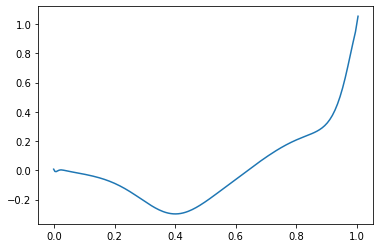

In [92]:
y_arr=yy.T[:,50]
u_arr=U_array[99].T[:,130]
plt.plot(y_arr,u_arr)

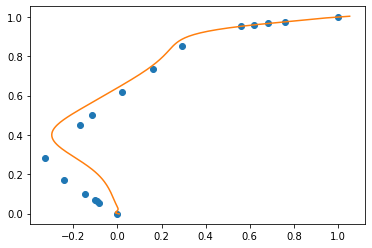

In [93]:
ghia = np.array(np.mat('1.0000  1.00000  1.00000  1.00000  1.00000  1.00000  1.00000  1.00000;0.9766  0.84123  0.75837  0.65928  0.53236  0.48223  0.47244  0.47221;0.9688  0.78871  0.68439  0.57492  0.48296  0.46120  0.47048  0.47783;0.9609  0.73722  0.61756  0.51117  0.46547  0.45992  0.47323  0.48070;0.9531  0.68717  0.55892  0.46604  0.46101  0.46036  0.47167  0.47804;0.8516  0.23151  0.29093  0.33304  0.34682  0.33556  0.34228  0.34635;0.7344  0.00332  0.16256  0.18719  0.19791  0.20087  0.20591  0.20673;0.6172 -0.13641  0.02135  0.05702  0.07156  0.08183  0.08342  0.08344;0.5000 -0.20581 -0.11477 -0.06080 -0.04272 -0.03039 -0.03800  0.03111;0.4531 -0.21090 -0.17119 -0.10648 -0.86636 -0.07404 -0.07503 -0.07540;0.2813 -0.15662 -0.32726 -0.27805 -0.24427 -0.22855 -0.23176 -0.23186;0.1719 -0.10150 -0.24299 -0.38289 -0.34323 -0.33050 -0.32393 -0.32709;0.1016 -0.06434 -0.14612 -0.29730 -0.41933 -0.40435 -0.38324 -0.38000;0.0703 -0.04775 -0.10338 -0.22220 -0.37827 -0.43643 -0.43025 -0.41657;0.0625 -0.04192 -0.09266 -0.20196 -0.35344 -0.42901 -0.43590 -0.42537;0.0547 -0.03717 -0.08186 -0.18109 -0.32407 -0.41165 -0.43154 -0.42735;0.0000  0.00000  0.00000  0.00000  0.00000  0.00000  0.00000  0.00000'))
plt.figure()
plt.plot(ghia[:,2], ghia[:,0],'o')
plt.plot(u_arr,y_arr,'-')
plt.show()

# Now we use the code for Channel Flow

In [10]:
def Channel_bc(P,U,V,U_in,P_fix):
    m,n=np.shape(P)
    # Inlet bc
    P[0,:]=P[1,:]
    U[0,:]=2.0*U_in-U[1,:]
    V[0,:]=(-1.0)*V[1,:]
    
    # Outlet bc 
    P[m-1,:]=P_fix
    U[m-1,:]=(1.0)*U[m-2,:]
    V[m-1,:]=(1.0)*V[m-2,:]
    
    # Wall 3 bc
    P[:,0]=P[:,1]
    U[:,0]=(-1.0)*U[:,1]
    V[:,0]=(-1.0)*V[:,1]
    
    # Wall 4 bc
    P[:,n-1]=P[:,n-2]
    U[:,n-1]=(-1.0)*U[:,n-2]
    V[:,n-1]=(-1.0)*V[:,n-2]
    

    
    return P,U,V

In [95]:
diameter=2
length=20*diameter
x=np.linspace(0,length,200)
y=np.linspace(0,diameter,20)
U_in=1.0
P_out=0.0
x_c,y_c,dx,dy,xx,yy,P,U,V=init_domains(x,y,U_in,P_out)
print(len(dx),len(dy))
rho=1.0
Re=400
nu=U_in*diameter/Re
beta=500
n_iter=700000
n_print=1000
n_save=7000
timestep=1e-5

P_array=[]
U_array=[]
V_array=[]
for i in range(n_iter):
    P,U,V=TVD_RK2_integrate(Channel_bc,P,U,V,U_in,P_out,timestep,rho,nu,beta,dx,dy)
    if i%n_print==0:
        print("Iteration "+str(i+1)+"completed")
        div_mat=compute_divergence(U,V,dx,dy)
        print("The maximum value of divergence is :"+str(np.max(np.abs(div_mat))))
    if i%n_save==0:
        print("Iteration "+str(i+1)+"saved")
        P_array.append(np.copy(P))
        U_array.append(np.copy(U))
        V_array.append(np.copy(V))


201 21
Iteration 1completed
The maximum value of divergence is :1.7381517748094816e-37
Iteration 1saved
Iteration 1001completed
The maximum value of divergence is :0.00037106417894948164
Iteration 2001completed
The maximum value of divergence is :0.004255804172983758
Iteration 3001completed
The maximum value of divergence is :0.008165946785418526
Iteration 4001completed
The maximum value of divergence is :0.008754436141737099
Iteration 5001completed
The maximum value of divergence is :0.008657196556503648
Iteration 6001completed
The maximum value of divergence is :0.012719634329736662
Iteration 7001completed
The maximum value of divergence is :0.011082598826141033
Iteration 7001saved
Iteration 8001completed
The maximum value of divergence is :0.010011657719975971
Iteration 9001completed
The maximum value of divergence is :0.008444629336046117
Iteration 10001completed
The maximum value of divergence is :0.007694786886481678
Iteration 11001completed
The maximum value of divergence is :0.

Iteration 97001completed
The maximum value of divergence is :0.004784932656218787
Iteration 98001completed
The maximum value of divergence is :0.004812190642183469
Iteration 98001saved
Iteration 99001completed
The maximum value of divergence is :0.004803988134547014
Iteration 100001completed
The maximum value of divergence is :0.004776830577342426
Iteration 101001completed
The maximum value of divergence is :0.004810162150453005
Iteration 102001completed
The maximum value of divergence is :0.004730221697513537
Iteration 103001completed
The maximum value of divergence is :0.004803729891711937
Iteration 104001completed
The maximum value of divergence is :0.004774731038741882
Iteration 105001completed
The maximum value of divergence is :0.004785076076553624
Iteration 105001saved
Iteration 106001completed
The maximum value of divergence is :0.004766226931206367
Iteration 107001completed
The maximum value of divergence is :0.004754690718830369
Iteration 108001completed
The maximum value of 

Iteration 192001completed
The maximum value of divergence is :0.003376142743692051
Iteration 193001completed
The maximum value of divergence is :0.003414528506049832
Iteration 194001completed
The maximum value of divergence is :0.003381015224263178
Iteration 195001completed
The maximum value of divergence is :0.003186274955605862
Iteration 196001completed
The maximum value of divergence is :0.003149918564101174
Iteration 196001saved
Iteration 197001completed
The maximum value of divergence is :0.003065611699402983
Iteration 198001completed
The maximum value of divergence is :0.0032771271891122
Iteration 199001completed
The maximum value of divergence is :0.0033507601429950164
Iteration 200001completed
The maximum value of divergence is :0.003356276403580133
Iteration 201001completed
The maximum value of divergence is :0.0034660650450177477
Iteration 202001completed
The maximum value of divergence is :0.003308982345389708
Iteration 203001completed
The maximum value of divergence is :0.0

Iteration 287001completed
The maximum value of divergence is :0.003171876132735858
Iteration 287001saved
Iteration 288001completed
The maximum value of divergence is :0.0030241918539596017
Iteration 289001completed
The maximum value of divergence is :0.003116285858908093
Iteration 290001completed
The maximum value of divergence is :0.0036243989389570263
Iteration 291001completed
The maximum value of divergence is :0.0034300045592480814
Iteration 292001completed
The maximum value of divergence is :0.0030429778083901388
Iteration 293001completed
The maximum value of divergence is :0.00300250042648382
Iteration 294001completed
The maximum value of divergence is :0.0032087589312516014
Iteration 294001saved
Iteration 295001completed
The maximum value of divergence is :0.0030431907066360265
Iteration 296001completed
The maximum value of divergence is :0.0029872383276082037
Iteration 297001completed
The maximum value of divergence is :0.0033167177399734604
Iteration 298001completed
The maximu

Iteration 382001completed
The maximum value of divergence is :0.005484253636724957
Iteration 383001completed
The maximum value of divergence is :0.005233181267318594
Iteration 384001completed
The maximum value of divergence is :0.005422759102228572
Iteration 385001completed
The maximum value of divergence is :0.005493670569810927
Iteration 385001saved
Iteration 386001completed
The maximum value of divergence is :0.00549531010011159
Iteration 387001completed
The maximum value of divergence is :0.005410898127739489
Iteration 388001completed
The maximum value of divergence is :0.0053449713022978625
Iteration 389001completed
The maximum value of divergence is :0.0052484100246339566
Iteration 390001completed
The maximum value of divergence is :0.0051966273983356116
Iteration 391001completed
The maximum value of divergence is :0.005300892300179383
Iteration 392001completed
The maximum value of divergence is :0.005351406570113594
Iteration 392001saved
Iteration 393001completed
The maximum val

Iteration 477001completed
The maximum value of divergence is :0.003881428784432678
Iteration 478001completed
The maximum value of divergence is :0.004240842884036499
Iteration 479001completed
The maximum value of divergence is :0.00431831217773709
Iteration 480001completed
The maximum value of divergence is :0.004053714623032752
Iteration 481001completed
The maximum value of divergence is :0.0039654329923429835
Iteration 482001completed
The maximum value of divergence is :0.0038898995398985834
Iteration 483001completed
The maximum value of divergence is :0.003799048198723831
Iteration 483001saved
Iteration 484001completed
The maximum value of divergence is :0.004049715801135122
Iteration 485001completed
The maximum value of divergence is :0.004377149375917697
Iteration 486001completed
The maximum value of divergence is :0.003993940064004503
Iteration 487001completed
The maximum value of divergence is :0.0037570382743751397
Iteration 488001completed
The maximum value of divergence is :0

Iteration 572001completed
The maximum value of divergence is :0.002443184876469306
Iteration 573001completed
The maximum value of divergence is :0.0023125523289022317
Iteration 574001completed
The maximum value of divergence is :0.0024580058839260483
Iteration 574001saved
Iteration 575001completed
The maximum value of divergence is :0.002309517346772191
Iteration 576001completed
The maximum value of divergence is :0.002249685410957109
Iteration 577001completed
The maximum value of divergence is :0.0022962426302667502
Iteration 578001completed
The maximum value of divergence is :0.0023187153634568296
Iteration 579001completed
The maximum value of divergence is :0.0022442612181817947
Iteration 580001completed
The maximum value of divergence is :0.0021864843248013237
Iteration 581001completed
The maximum value of divergence is :0.002337726441521561
Iteration 581001saved
Iteration 582001completed
The maximum value of divergence is :0.0021772190289373627
Iteration 583001completed
The maximu

Iteration 667001completed
The maximum value of divergence is :0.002092460870536086
Iteration 668001completed
The maximum value of divergence is :0.002038886857066037
Iteration 669001completed
The maximum value of divergence is :0.0019353756219067568
Iteration 670001completed
The maximum value of divergence is :0.0018573214527993049
Iteration 671001completed
The maximum value of divergence is :0.001968539790175167
Iteration 672001completed
The maximum value of divergence is :0.0019489770112206314
Iteration 672001saved
Iteration 673001completed
The maximum value of divergence is :0.001934755853551816
Iteration 674001completed
The maximum value of divergence is :0.001897215462044997
Iteration 675001completed
The maximum value of divergence is :0.0018905557509052435
Iteration 676001completed
The maximum value of divergence is :0.0018778508712526988
Iteration 677001completed
The maximum value of divergence is :0.0018984581880872506
Iteration 678001completed
The maximum value of divergence i

In [107]:
def plotter(ind):
    plt.contourf(xx,yy,U_array[ind])
    #plt.streamplot(xx.T,yy.T,U_array[ind].T,V_array[ind].T)
    plt.colorbar()
    
D=interact(plotter,ind=IntSlider(min=0,max=len(U_array)-1,step=1))

interactive(children=(IntSlider(value=0, description='ind', max=99), Output()), _dom_classes=('widget-interact…

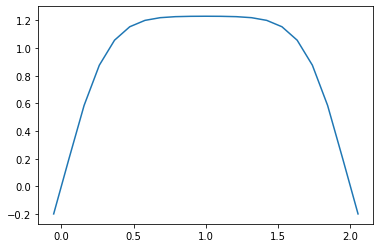

In [106]:
y_arr=yy.T[:,50]
u_arr=U_array[99].T[:,200]
plt.plot(y_arr,u_arr)

# Solving for external flow problems

In [11]:
def External_flow_bc(P,U,V,U_in,P_fix):
    m,n=np.shape(P)
    # Inlet bc
    P[0,:]=P[1,:]
    U[0,:]=2.0*U_in-U[1,:]
    V[0,:]=(-1.0)*V[1,:]
    
    # Outlet bc 
    P[m-1,:]=P_fix
    U[m-1,:]=(1.0)*U[m-2,:]
    V[m-1,:]=(1.0)*V[m-2,:]
    
    # Wall 3 bc
    P[:,0]=P[:,1]
    U[:,0]=(1.0)*U[:,1]
    V[:,0]=(-1.0)*V[:,1]
    
    # Wall 4 bc
    P[:,n-1]=P[:,n-2]
    U[:,n-1]=(1.0)*U[:,n-2]
    V[:,n-1]=(-1.0)*V[:,n-2]
    

    
    return P,U,V

In [12]:
def Convective_outlet_flow_bc(P,U,V,U_in,P_fix):
    m,n=np.shape(P)
    # Inlet bc
    P[0,:]=P[1,:]
    U[0,:]=2.0*U_in-U[1,:]
    V[0,:]=(-1.0)*V[1,:]
    
    # Outlet bc 
    P[m-1,:]=P_fix
    V[m-1,:]=(1.0)*V[m-2,:]
    
    # Wall 3 bc
    P[:,0]=P[:,1]
    U[:,0]=(1.0)*U[:,1]
    V[:,0]=(-1.0)*V[:,1]
    
    # Wall 4 bc
    P[:,n-1]=P[:,n-2]
    U[:,n-1]=(1.0)*U[:,n-2]
    V[:,n-1]=(-1.0)*V[:,n-2]
    

    
    return P,U,V

def convective_outlet_forcing(U,U_in,dx):
    der_u=np.zeros_like(U)
    m,n=np.shape(U)
    dx_l=0.5*(dx[m-1]+dx[m-2])
    for j in range(1,n-1):
        der_u[m-1,j]=(-1.0*U_in)*(U[m-1,j]-U[m-2,j])/dx_l
    return der_u
    

In [13]:
def IBM_integrate_time_convec_outlet(P_state,U_state,V_state,U_bound,P_bound,timestep,rho,nu,beta,dx,dy,x_c,y_c,lag_x,lag_y):
    dp,du1,dv1=CFD_EDACM(P_state,U_state,V_state,rho,nu,beta,dx,dy)
    du2,dv2=IBM_forcing_der(U_state,V_state,x_c,y_c,lag_x,lag_y,timestep)
    du3=convective_outlet_forcing(U_state,U_bound,dx)
    
    P_temp=P_state+timestep*dp
    U_temp=U_state+timestep*(du1+du2+du3)
    V_temp=V_state+timestep*(dv1+dv2)
    
    P_temp,U_temp,V_temp=Convective_outlet_flow_bc(P_temp,U_temp,V_temp,U_bound,P_bound)
    
    dp,du1,dv1=CFD_EDACM(P_temp,U_temp,V_temp,rho,nu,beta,dx,dy)
    du2,dv2=IBM_forcing_der(U_temp,V_temp,x_c,y_c,lag_x,lag_y,timestep)
    du3=convective_outlet_forcing(U_temp,U_bound,dx)
    
    P_new=0.5*(P_state+P_temp)+0.5*timestep*dp
    U_new=0.5*(U_state+U_temp)+0.5*timestep*(du1+du2+du3)
    V_new=0.5*(V_state+V_temp)+0.5*timestep*(dv1+dv2)
    
    P_new,U_new,V_new=Convective_outlet_flow_bc(P_new,U_new,V_new,U_bound,P_bound)
    
    return P_new,U_new,V_new

In [1]:
def create_euler_domains(params):
    dim=params["dim"]
    factor_conc=params["conc_region"]
    factor_inlet=params["in_region"]
    factor_outlet=params["out_region"]
    factor_wall=params["wall_region"]
    div_conc=params["step_conc"] # Number of divisions in conc region
    div_in=params["step_in"] # Number of divisions in inlet region
    div_out=params["step_out"] # Number of divisions in outlet region
    div_wall=params["step_wall"] # Number of divisions in wall region
    
    x=np.concatenate([np.linspace(-1.0*factor_inlet*dim,-1.0*factor_conc*dim,div_in),np.linspace(-1.0*factor_conc*dim,1.0*factor_conc*dim,div_conc)[1:-1],np.linspace(1.0*factor_conc*dim,1.0*factor_outlet*dim,div_out)])
    y=np.concatenate([np.linspace(-1.0*factor_wall*dim,-1.0*factor_conc*dim,div_wall),np.linspace(-1.0*factor_conc*dim,1.0*factor_conc*dim,div_conc)[1:-1],np.linspace(1.0*factor_conc*dim,1.0*factor_wall*dim,div_wall)])
    
    return x,y

In [15]:
 def create_circle(radius,div):
        dang=div/radius
        ang=np.arange(0,2*np.pi-0.1*dang,dang)
        x=radius*np.cos(ang)
        y=radius*np.sin(ang)
        return x,y

# Now we try flow past a cylinder

In [52]:
radius=0.75
dim=2.0*radius
Re=100.0
rho=1.0
beta=400.0
U_in=5.0
P_out=0.0
params=dict()
params["dim"]=dim
params["conc_region"]=2.5
params["in_region"]=8.0
params["out_region"]=15.0
params["wall_region"]=6.0
params["step_conc"]=80
params["step_in"]=60
params["step_out"]=200
params["step_wall"]=50
x_eu,y_eu=create_euler_domains(params)

In [53]:
x_c,y_c,dx,dy,xx,yy,P,U,V=init_domains(x_eu,y_eu,U_in,P_out)
lag_x,lag_y=create_circle(radius,min(dx))

In [54]:
timestep=1e-5
n_iter=800000
n_print=1000
n_save=80000

In [55]:
nu=U_in*dim/Re

In [56]:
P_array=[]
U_array=[]
V_array=[]
for i in range(n_iter):
    P,U,V=IBM_integrate_time_convec_outlet(P,U,V,U_in,P_out,timestep,rho,nu,beta,dx,dy,x_c,y_c,lag_x,lag_y)
    if i%n_print==0:
        print("Iteration "+str(i+1)+"completed")
        div_mat=compute_divergence(U,V,dx,dy)
        print("The maximum value of divergence is :"+str(np.max(np.abs(div_mat))))
        fx,fy=IBM_force_computation(U,V,x_c,y_c,lag_x,lag_y,timestep,rho)
        print("The force in the x direction is: "+str(fx))
        print("The force in the y direction is: "+str(fy))
    if i%n_save==0:
        print("Iteration "+str(i+1)+"saved")
        P_array.append(np.copy(P))
        U_array.append(np.copy(U))
        V_array.append(np.copy(V))


Iteration 1completed
The maximum value of divergence is :10.680231100492474
The force in the x direction is: 155651.32487879627
The force in the y direction is: 0.0
Iteration 1saved
Iteration 1001completed
The maximum value of divergence is :19.98540584643588
The force in the x direction is: 469.04628336879665
The force in the y direction is: -0.010818067413961296
Iteration 2001completed
The maximum value of divergence is :25.052614520086415
The force in the x direction is: 451.5243230072028
The force in the y direction is: -0.0017981501947241796
Iteration 3001completed
The maximum value of divergence is :18.8422918244376
The force in the x direction is: 404.67935775750476
The force in the y direction is: 0.002725276620524575
Iteration 4001completed
The maximum value of divergence is :27.038758477989234
The force in the x direction is: 366.9331241118574
The force in the y direction is: 0.010207401726435084
Iteration 5001completed
The maximum value of divergence is :22.37296643690161
Th

Iteration 45001completed
The maximum value of divergence is :6.199408094615761
The force in the x direction is: 39.373624948735326
The force in the y direction is: 0.04140119856692985
Iteration 46001completed
The maximum value of divergence is :6.456447873566399
The force in the x direction is: -4.914535057188744
The force in the y direction is: 0.05364975591142351
Iteration 47001completed
The maximum value of divergence is :5.435124986945008
The force in the x direction is: -33.715234151669726
The force in the y direction is: 0.05337290195787703
Iteration 48001completed
The maximum value of divergence is :3.038835072040553
The force in the x direction is: -44.68205543607719
The force in the y direction is: 0.04645287183638547
Iteration 49001completed
The maximum value of divergence is :2.6453049028292908
The force in the x direction is: -42.74327224577619
The force in the y direction is: 0.03651466044888252
Iteration 50001completed
The maximum value of divergence is :4.835513235458211

Iteration 90001completed
The maximum value of divergence is :1.9738575555494835
The force in the x direction is: 18.36947344007268
The force in the y direction is: 0.01104085058607196
Iteration 91001completed
The maximum value of divergence is :2.230419281244296
The force in the x direction is: 36.21834271841361
The force in the y direction is: 0.00023969843526383539
Iteration 92001completed
The maximum value of divergence is :2.0794291221958328
The force in the x direction is: 52.55911151914682
The force in the y direction is: -0.006168892521139724
Iteration 93001completed
The maximum value of divergence is :1.6308357272485838
The force in the x direction is: 63.71858712746958
The force in the y direction is: -0.006587132656099785
Iteration 94001completed
The maximum value of divergence is :1.6210497374064037
The force in the x direction is: 67.39780936659818
The force in the y direction is: -0.0010938535695103613
Iteration 95001completed
The maximum value of divergence is :1.61140264

Iteration 135001completed
The maximum value of divergence is :0.606504661475881
The force in the x direction is: 25.91182969752794
The force in the y direction is: 0.0027168214282977665
Iteration 136001completed
The maximum value of divergence is :0.6890138292323291
The force in the x direction is: 21.391094377365114
The force in the y direction is: 0.0091859146553816
Iteration 137001completed
The maximum value of divergence is :0.7303936134069401
The force in the x direction is: 17.42316510450199
The force in the y direction is: 0.013355239542130276
Iteration 138001completed
The maximum value of divergence is :0.7182508408548957
The force in the x direction is: 15.102150780870955
The force in the y direction is: 0.014232477394577642
Iteration 139001completed
The maximum value of divergence is :0.6833405608779337
The force in the x direction is: 15.06788187814236
The force in the y direction is: 0.011649639066242168
Iteration 140001completed
The maximum value of divergence is :0.711797

Iteration 179001completed
The maximum value of divergence is :0.6174584329367541
The force in the x direction is: 23.83382925018742
The force in the y direction is: -0.013574609045803543
Iteration 180001completed
The maximum value of divergence is :0.6222362334145828
The force in the x direction is: 25.408681302303563
The force in the y direction is: -0.01725685680720951
Iteration 181001completed
The maximum value of divergence is :0.6187146458546309
The force in the x direction is: 27.680831767816763
The force in the y direction is: -0.02155169977347754
Iteration 182001completed
The maximum value of divergence is :0.6037631822013125
The force in the x direction is: 30.1663386159439
The force in the y direction is: -0.025611603579614534
Iteration 183001completed
The maximum value of divergence is :0.6393456879029722
The force in the x direction is: 32.35160175879274
The force in the y direction is: -0.028629316037356523
Iteration 184001completed
The maximum value of divergence is :0.57

...

Iteration 531001completed
The maximum value of divergence is :0.5505018341186876
The force in the x direction is: 26.982851041282203
The force in the y direction is: 0.027905010524601537
Iteration 532001completed
The maximum value of divergence is :0.5408995832746797
The force in the x direction is: 27.53886317208491
The force in the y direction is: 0.0282909000657232
Iteration 533001completed
The maximum value of divergence is :0.5293859191738761
The force in the x direction is: 27.856362733492332
The force in the y direction is: 0.028635221095583654
Iteration 534001completed
The maximum value of divergence is :0.5175392402089898
The force in the x direction is: 27.95109835876031
The force in the y direction is: 0.02895522103368804
Iteration 535001completed
The maximum value of divergence is :0.506899346853622
The force in the x direction is: 27.856207624692832
The force in the y direction is: 0.02928186001731091
Iteration 536001completed
The maximum value of divergence is :0.49860590

Iteration 575001completed
The maximum value of divergence is :0.5299617695865102
The force in the x direction is: 28.836065883872543
The force in the y direction is: 0.026198475032632736
Iteration 576001completed
The maximum value of divergence is :0.525228233995712
The force in the x direction is: 29.102413624376748
The force in the y direction is: 0.025506871114520088
Iteration 577001completed
The maximum value of divergence is :0.5182137678806278
The force in the x direction is: 29.32711117528025
The force in the y direction is: 0.02478017265441168
Iteration 578001completed
The maximum value of divergence is :0.509321763358372
The force in the x direction is: 29.449742224507535
The force in the y direction is: 0.024022240498406712
Iteration 579001completed
The maximum value of divergence is :0.499205284926898
The force in the x direction is: 29.41202289777155
The force in the y direction is: 0.023231845022619213
Iteration 580001completed
The maximum value of divergence is :0.4886825

Iteration 619001completed
The maximum value of divergence is :0.49945087484822537
The force in the x direction is: 28.095879951626316
The force in the y direction is: -0.02394231850180706
Iteration 620001completed
The maximum value of divergence is :0.49537924973711256
The force in the x direction is: 27.555858214851888
The force in the y direction is: -0.024864131382208804
Iteration 621001completed
The maximum value of divergence is :0.49268104202629814
The force in the x direction is: 26.90811350146352
The force in the y direction is: -0.02581758906763397
Iteration 622001completed
The maximum value of divergence is :0.49115474499505396
The force in the x direction is: 26.199813507030964
The force in the y direction is: -0.026840346170831322
Iteration 623001completed
The maximum value of divergence is :0.4905746847088821
The force in the x direction is: 25.476761273167376
The force in the y direction is: -0.02795195331206489
Iteration 624001completed
The maximum value of divergence is

Iteration 663001completed
The maximum value of divergence is :0.5498588522619237
The force in the x direction is: 18.529020718353042
The force in the y direction is: -0.06783032076715408
Iteration 664001completed
The maximum value of divergence is :0.5681299551382502
The force in the x direction is: 18.52035214735107
The force in the y direction is: -0.06714643591817272
Iteration 665001completed
The maximum value of divergence is :0.5834753330033884
The force in the x direction is: 18.743318342130745
The force in the y direction is: -0.06607965430094964
Iteration 666001completed
The maximum value of divergence is :0.5949085641783576
The force in the x direction is: 19.181862926532336
The force in the y direction is: -0.06476680258319982
Iteration 667001completed
The maximum value of divergence is :0.6017055612523698
The force in the x direction is: 19.806667036832614
The force in the y direction is: -0.06338673954406801
Iteration 668001completed
The maximum value of divergence is :0.60

KeyboardInterrupt: 

In [63]:
def plotter(ind):
    plt.figure(figsize=(16,8))
    plt.contourf(xx,yy,U_array[ind],levels=20)
    #plt.streamplot(xx.T,yy.T,U_array[ind].T,V_array[ind].T)
    plt.colorbar()
    
D=interact(plotter,ind=IntSlider(min=0,max=len(U_array)-1,step=1))

interactive(children=(IntSlider(value=0, description='ind', max=8), Output()), _dom_classes=('widget-interact'…

Using matplotlib backend: Qt5Agg


# Now we try flow past airfoil

In [18]:
def NACA_sym_airfoil(chord_length,spacing,thickness):
    t=0.01*thickness*chord_length
    x=np.arange(0,chord_length-0.1*spacing,spacing)
    x_n=x/chord_length
    factor_root=5*0.2969
    factor_1=5*(-0.1260)
    factor_2=5*(-0.3516)
    factor_3=5*(0.2843)
    factor_4=5*(-0.1015)
    y=t*(factor_root*(x_n**0.5)+factor_1*x_n+factor_2*(x_n**2)+factor_3*(x_n**3)+factor_4*(x_n**4))
    lag_x=np.concatenate([x,x])
    lag_y=np.concatenate([y,-y])
    return lag_x,lag_y

In [4]:
radius=0.75
dim=2.0*radius
Re=100.0
rho=1.0
beta=400.0
U_in=5.0
P_out=0.0
params=dict()
params["dim"]=dim
params["conc_region"]=2.5
params["in_region"]=8.0
params["out_region"]=15.0
params["wall_region"]=6.0
params["step_conc"]=120
params["step_in"]=60
params["step_out"]=200
params["step_wall"]=50
x_eu,y_eu=create_euler_domains(params)

In [5]:
x_c,y_c,dx,dy,xx,yy,P,U,V=init_domains(x_eu,y_eu,U_in,P_out)
lag_x,lag_y=NACA_sym_airfoil(dim,min(dx),12)

In [7]:
dy

array([0.10714286, 0.10714286, 0.10714286, 0.10714286, 0.10714286,
       0.10714286, 0.10714286, 0.10714286, 0.10714286, 0.10714286,
       0.10714286, 0.10714286, 0.10714286, 0.10714286, 0.10714286,
       0.10714286, 0.10714286, 0.10714286, 0.10714286, 0.10714286,
       0.10714286, 0.10714286, 0.10714286, 0.10714286, 0.10714286,
       0.10714286, 0.10714286, 0.10714286, 0.10714286, 0.10714286,
       0.10714286, 0.10714286, 0.10714286, 0.10714286, 0.10714286,
       0.10714286, 0.10714286, 0.10714286, 0.10714286, 0.10714286,
       0.10714286, 0.10714286, 0.10714286, 0.10714286, 0.10714286,
       0.10714286, 0.10714286, 0.10714286, 0.10714286, 0.10714286,
       0.06302521, 0.06302521, 0.06302521, 0.06302521, 0.06302521,
       0.06302521, 0.06302521, 0.06302521, 0.06302521, 0.06302521,
       0.06302521, 0.06302521, 0.06302521, 0.06302521, 0.06302521,
       0.06302521, 0.06302521, 0.06302521, 0.06302521, 0.06302521,
       0.06302521, 0.06302521, 0.06302521, 0.06302521, 0.06302

In [33]:
timestep=1e-5
n_iter=800000
n_print=1000
n_save=80000
nu=U_in*dim/Re

In [34]:
P_array=[]
U_array=[]
V_array=[]
for i in range(n_iter):
    P,U,V=IBM_integrate_time_convec_outlet(P,U,V,U_in,P_out,timestep,rho,nu,beta,dx,dy,x_c,y_c,lag_x,lag_y)
    if i%n_print==0:
        print("Iteration "+str(i+1)+"completed")
        div_mat=compute_divergence(U,V,dx,dy)
        print("The maximum value of divergence is :"+str(np.max(np.abs(div_mat))))
        fx,fy=IBM_force_computation(U,V,x_c,y_c,lag_x,lag_y,timestep,rho)
        print("The force in the x direction is: "+str(fx))
        print("The force in the y direction is: "+str(fy))
    if i%n_save==0:
        print("Iteration "+str(i+1)+"saved")
        P_array.append(np.copy(P))
        U_array.append(np.copy(U))
        V_array.append(np.copy(V))


Iteration 1completed
The maximum value of divergence is :21.041568812867425
The force in the x direction is: 62087.03365752462
The force in the y direction is: 0.0
Iteration 1saved
Iteration 1001completed
The maximum value of divergence is :21.03469160106428
The force in the x direction is: 41.80667802072808
The force in the y direction is: 7.105427357601002e-14
Iteration 2001completed
The maximum value of divergence is :8.123477957030707
The force in the x direction is: 28.002778291278535
The force in the y direction is: 0.0
Iteration 3001completed
The maximum value of divergence is :5.854605005999725
The force in the x direction is: 24.495072092913404
The force in the y direction is: 5.595524044110789e-14
Iteration 4001completed
The maximum value of divergence is :4.253351712550349
The force in the x direction is: 20.82000166152342
The force in the y direction is: -7.993605777301127e-15
Iteration 5001completed
The maximum value of divergence is :3.4642660736565754
The force in the x 

Iteration 45001completed
The maximum value of divergence is :2.681911066889546
The force in the x direction is: 9.428234265009902
The force in the y direction is: 3.552713678800501e-15
Iteration 46001completed
The maximum value of divergence is :2.6767572464365905
The force in the x direction is: 9.408314617318304
The force in the y direction is: -5.773159728050814e-15
Iteration 47001completed
The maximum value of divergence is :2.6717869627952755
The force in the x direction is: 9.389049237675374
The force in the y direction is: -2.4424906541753444e-15
Iteration 48001completed
The maximum value of divergence is :2.6670000364284583
The force in the x direction is: 9.37053161191413
The force in the y direction is: -2.9531932455029164e-14
Iteration 49001completed
The maximum value of divergence is :2.6624515527760426
The force in the x direction is: 9.35286563768196
The force in the y direction is: -2.708944180085382e-14
Iteration 50001completed
The maximum value of divergence is :2.6582

Iteration 89001completed
The maximum value of divergence is :2.5448447787977404
The force in the x direction is: 8.893652086390421
The force in the y direction is: -6.8833827526759706e-15
Iteration 90001completed
The maximum value of divergence is :2.534701823715281
The force in the x direction is: 8.891203094209837
The force in the y direction is: 7.549516567451064e-15
Iteration 91001completed
The maximum value of divergence is :2.5284887923835377
The force in the x direction is: 8.916230490678359
The force in the y direction is: 3.064215547965432e-14
Iteration 92001completed
The maximum value of divergence is :2.531533294583273
The force in the x direction is: 8.979331501743582
The force in the y direction is: -1.8207657603852567e-14
Iteration 93001completed
The maximum value of divergence is :2.5485586184759264
The force in the x direction is: 9.079973391990272
The force in the y direction is: -1.6431300764452317e-14
Iteration 94001completed
The maximum value of divergence is :2.580

Iteration 133001completed
The maximum value of divergence is :2.529111068384644
The force in the x direction is: 8.628448894911203
The force in the y direction is: 1.6431300764452317e-14
Iteration 134001completed
The maximum value of divergence is :2.5260739953715188
The force in the x direction is: 8.540682843633702
The force in the y direction is: -6.439293542825908e-15
Iteration 135001completed
The maximum value of divergence is :2.530083623071951
The force in the x direction is: 8.49687853751824
The force in the y direction is: 1.709743457922741e-14
Iteration 136001completed
The maximum value of divergence is :2.53949065753984
The force in the x direction is: 8.497715274140317
The force in the y direction is: 3.219646771412954e-14
Iteration 137001completed
The maximum value of divergence is :2.551447030848758
The force in the x direction is: 8.535483862702275
The force in the y direction is: 3.441691376337985e-14
Iteration 138001completed
The maximum value of divergence is :2.56259

Iteration 177001completed
The maximum value of divergence is :2.5388122263799495
The force in the x direction is: 8.805613368511198
The force in the y direction is: -2.4202861936828413e-14
Iteration 178001completed
The maximum value of divergence is :2.5350376397674843
The force in the x direction is: 8.794409107452207
The force in the y direction is: -1.7763568394002505e-14
Iteration 179001completed
The maximum value of divergence is :2.5294549353056777
The force in the x direction is: 8.776917739729216
The force in the y direction is: -3.3306690738754696e-15
Iteration 180001completed
The maximum value of divergence is :2.52395690565214
The force in the x direction is: 8.759978444995813
The force in the y direction is: -3.108624468950438e-14
Iteration 181001completed
The maximum value of divergence is :2.52001944046952
The force in the x direction is: 8.748955276563185
The force in the y direction is: 8.43769498715119e-15
Iteration 182001completed
The maximum value of divergence is :2

...

Iteration 397001completed
The maximum value of divergence is :2.5639619028939364
The force in the x direction is: 9.048844733062234
The force in the y direction is: 2.7533531010703882e-14
Iteration 398001completed
The maximum value of divergence is :2.569978580589032
The force in the x direction is: 9.034174171906283
The force in the y direction is: 1.9095836023552692e-14
Iteration 399001completed
The maximum value of divergence is :2.5747995904413266
The force in the x direction is: 9.003622885328335
The force in the y direction is: 2.55351295663786e-14
Iteration 400001completed
The maximum value of divergence is :2.5779839023064106
The force in the x direction is: 8.957482282058171
The force in the y direction is: 4.3520742565306136e-14
Iteration 400001saved
Iteration 401001completed
The maximum value of divergence is :2.5791050828938236
The force in the x direction is: 8.89759603117025
The force in the y direction is: -2.886579864025407e-15
Iteration 402001completed
The maximum valu

Iteration 441001completed
The maximum value of divergence is :2.537785082579715
The force in the x direction is: 8.917710152010475
The force in the y direction is: 2.5757174171303632e-14
Iteration 442001completed
The maximum value of divergence is :2.543707377360297
The force in the x direction is: 8.943792873732363
The force in the y direction is: 1.865174681370263e-14
Iteration 443001completed
The maximum value of divergence is :2.549131276601962
The force in the x direction is: 8.964466238605691
The force in the y direction is: -6.439293542825908e-15
Iteration 444001completed
The maximum value of divergence is :2.553802480906411
The force in the x direction is: 8.979577569373262
The force in the y direction is: 2.90878432451791e-14
Iteration 445001completed
The maximum value of divergence is :2.5576502488039967
The force in the x direction is: 8.989097004161358
The force in the y direction is: -3.9968028886505635e-15
Iteration 446001completed
The maximum value of divergence is :2.56

Iteration 485001completed
The maximum value of divergence is :2.5137439192567896
The force in the x direction is: 8.60437438536404
The force in the y direction is: 4.884981308350689e-15
Iteration 486001completed
The maximum value of divergence is :2.512410701633563
The force in the x direction is: 8.596620362650885
The force in the y direction is: -7.771561172376096e-15
Iteration 487001completed
The maximum value of divergence is :2.5112332943185436
The force in the x direction is: 8.59104241969149
The force in the y direction is: -4.218847493575595e-14
Iteration 488001completed
The maximum value of divergence is :2.510339943488944
The force in the x direction is: 8.588317558568333
The force in the y direction is: -3.530509218307998e-14
Iteration 489001completed
The maximum value of divergence is :2.5098200612649446
The force in the x direction is: 8.588961590068118
The force in the y direction is: -2.1760371282653068e-14
Iteration 490001completed
The maximum value of divergence is :2.

Iteration 529001completed
The maximum value of divergence is :2.524231784595589
The force in the x direction is: 8.77497200602458
The force in the y direction is: 1.5987211554602254e-14
Iteration 530001completed
The maximum value of divergence is :2.525194396577458
The force in the x direction is: 8.786779224763302
The force in the y direction is: 1.8207657603852567e-14
Iteration 531001completed
The maximum value of divergence is :2.5251552834093154
The force in the x direction is: 8.790554395511615
The force in the y direction is: 7.771561172376096e-15
Iteration 532001completed
The maximum value of divergence is :2.524425626633839
The force in the x direction is: 8.787786624172131
The force in the y direction is: -3.9968028886505635e-15
Iteration 533001completed
The maximum value of divergence is :2.5234159476804177
The force in the x direction is: 8.780406310370754
The force in the y direction is: -2.731148640577885e-14
Iteration 534001completed
The maximum value of divergence is :2.

KeyboardInterrupt: 

In [37]:
def plotter(ind):
    plt.figure(figsize=(16,8))
    plt.contourf(xx,yy,U_array[ind],levels=20)
    #plt.streamplot(xx.T,yy.T,U_array[ind].T,V_array[ind].T)
    plt.colorbar()
    
D=interact(plotter,ind=IntSlider(min=0,max=len(U_array)-1,step=1))

interactive(children=(IntSlider(value=0, description='ind', max=7), Output()), _dom_classes=('widget-interact'…

In [36]:
%matplotlib auto

Using matplotlib backend: Qt5Agg


In [1]:
def CD(Re):
    return (24/Re)*(1+0.15*(Re**0.687))

In [2]:
CD(100)

1.0917310910948732